# 03 · TTC Schedule Analysis (Static GTFS)

Using the TTC's published timetable, this notebook calculates:

1. The **scheduled headway** of every route in each time period
2. Which routes belong to the **frequent network**
3. The **500 m walking catchment** of frequent stops, and which stops fall outside it (service gaps)

The results also serve as the baseline for the realtime analysis: once enough realtime data is collected, it is compared against this schedule ("planned vs. actual").

## 1. Settings

Change the date, the frequent-service threshold or the walking distance here.

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

GTFS = Path("../data/static")          # folder with the unzipped static GTFS
OUT = Path("../data/processed")        # outputs (inside data/, which is git-ignored)
OUT.mkdir(parents=True, exist_ok=True)

SERVICE_DATE = "20261021"   # a typical weekday (Wednesday); must fall within calendar.txt validity
FREQUENT_MIN = 10           # headway <= 10 minutes = frequent
WALK_M = 500                # walking distance in metres
CRS_M = "EPSG:2952"         # NAD83(CSRS) / MTM zone 10: metric projection commonly used for Toronto

# Time periods in hours; values above 24 are after midnight on the same service day (GTFS convention)
PERIODS = {
    "AM peak": (6, 9),
    "Midday": (9, 15),
    "PM peak": (15, 19),
    "Evening": (19, 22),
    "Late evening": (22, 25),
}
CORE_PERIODS = ["AM peak", "Midday", "PM peak"]   # all three must meet the threshold to count as frequent

# Study routes for the realtime analysis; this order is used in every table (local/express pairs side by side)
STUDY = ["504", "25", "29", "929", "39", "939"]

# Stop segment thresholds, as a share of the busiest stop on the same route and direction (heuristic, see section 6)
TRUNK_MIN = 0.75        # >= 75% of trips: trunk
OCCASIONAL_MAX = 0.25   # < 25% of trips: occasional (excluded from the baseline); in between: branch

## 2. Load GTFS

In [ ]:
def read(name):
    path = GTFS / f"{name}.txt"
    return pd.read_csv(path, dtype=str) if path.exists() else pd.DataFrame()

routes = read("routes")
trips = read("trips")
stop_times = read("stop_times")
stops = read("stops")
cal = read("calendar")
cal_dates = read("calendar_dates")

# direction_id is optional in GTFS; default to "0" so later steps still work
if "direction_id" not in trips.columns:
    trips["direction_id"] = "0"
trips["direction_id"] = trips["direction_id"].fillna("0")

for name, df in [("routes", routes), ("trips", trips), ("stop_times", stop_times), ("stops", stops)]:
    print(f"{name:11s} {len(df):>10,} rows")
if len(cal):
    print("Timetable valid from", cal["start_date"].min(), "to", cal["end_date"].max())

routes             230 rows
trips          129,271 rows
stop_times   4,131,941 rows
stops            9,128 rows
Timetable valid from 20260930 to 20261031


## 3. Select the trips that run on the chosen date

`calendar.txt` defines which days of the week and date range each `service_id` runs; `calendar_dates.txt` holds exceptions such as holidays (added or removed service).

In [ ]:
def active_services(date):
    weekday = pd.Timestamp(date).day_name().lower()   # e.g. "wednesday"
    active = set()
    if len(cal):
        ok = (cal["start_date"] <= date) & (cal["end_date"] >= date) & (cal[weekday] == "1")
        active |= set(cal.loc[ok, "service_id"])
    if len(cal_dates):
        cd = cal_dates[cal_dates["date"] == date]
        active |= set(cd.loc[cd["exception_type"] == "1", "service_id"])   # service added
        active -= set(cd.loc[cd["exception_type"] == "2", "service_id"])   # service removed
    return active

services = active_services(SERVICE_DATE)
day_trips = trips[trips["service_id"].isin(services)]
print(f"{SERVICE_DATE}: {len(services)} service_id(s), {len(day_trips):,} trips, {day_trips['route_id'].nunique()} routes")
assert len(day_trips) > 0, "No trips on this date: check that SERVICE_DATE is within the timetable's validity"


20261021: 1 service_id(s), 37,675 trips, 222 routes


## 4. Departure time of each trip

Each trip's departure from its **first stop** is used for the sanity checks below. GTFS times can exceed 24:00 (e.g. `25:10:00` = 1:10 am the next morning, still on this service day), so they are converted to minutes after midnight.

In [ ]:
def to_minutes(s):
    p = s.str.split(":", expand=True).astype(int)
    return p[0] * 60 + p[1] + p[2] / 60

st = stop_times[stop_times["trip_id"].isin(day_trips["trip_id"])].copy()
st["stop_sequence"] = st["stop_sequence"].astype(int)

first = (
    st.dropna(subset=["departure_time"])
      .sort_values("stop_sequence")
      .groupby("trip_id", as_index=False)
      .first()
)
first["dep_min"] = to_minutes(first["departure_time"])
first = first.merge(day_trips[["trip_id", "route_id", "direction_id"]], on="trip_id")

# Period edges in minutes (periods are contiguous: each one ends where the next starts)
edges = [a * 60 for a, _ in PERIODS.values()] + [list(PERIODS.values())[-1][1] * 60]

def assign_period(minutes):
    # [start, end): 9:00 belongs to Midday, not AM peak
    return pd.cut(minutes, bins=edges, labels=list(PERIODS), right=False).astype("object")

first["period"] = assign_period(first["dep_min"])
first[["trip_id", "route_id", "direction_id", "departure_time", "period"]].head()

,trip_id,route_id,direction_id,departure_time,period
0,100002020,16,0,16:50:00,PM peak
1,100005020,44,0,18:18:00,PM peak
2,100007020,44,1,17:07:00,PM peak
3,100012020,72,0,08:38:00,AM peak
4,100018020,94,1,17:42:00,PM peak


### Sanity checks

- **Late-night time format**: agencies write after-midnight trips either as `25:30` (same service day) or `01:30` (next service day). Both are valid GTFS.
- **Duplicates**: overlapping service_ids on the same day would double-count trips and make headways look too short.
- **Branches / short turns**: a route with several starting stops is a trunk with branches, so its combined headway is shorter than any single branch.

In [ ]:
print("Earliest departure:", first["departure_time"].min())
print("Latest departure:  ", first["departure_time"].max())
print("Trips starting at/after 24:00:", (first["dep_min"] >= 24 * 60).sum())
print("Trips starting 00:00-04:00:   ", (first["dep_min"] < 4 * 60).sum())

print("\nActive service_ids:", sorted(services))
dup = first.duplicated(subset=["route_id", "direction_id", "stop_id", "departure_time"], keep=False)
print("Possible duplicate trips:", dup.sum())

# Starting stops per route at midday (several = branches or short turns)
for r in ["63", "25", "47"]:
    match = routes.loc[routes["route_short_name"] == r, "route_id"]
    if match.empty:
        continue
    sub = first[(first["route_id"] == match.iloc[0]) & (first["period"] == "Midday")]
    print(f"\nRoute {r}: midday trips by starting stop")
    print(sub.merge(stops[["stop_id", "stop_name"]], on="stop_id")
             .groupby(["direction_id", "stop_name"]).size())

Earliest departure: 03:28:00
Latest departure:   30:09:00
Trips starting at/after 24:00: 2845
Trips starting 00:00-04:00:    24

Active service_ids: ['1']
Possible duplicate trips: 16

Route 63: midday trips by starting stop
direction_id  stop_name                       
0             Cedarvale Station at Bus Bay 7      55
              Oakwood Ave at St Clair Ave West     3
              Ossington Station at Bus Bay 6      57
1             Atlantic Ave at King St West        57
              Ossington Station at Bus Bay 2      57
dtype: int64

Route 25: midday trips by starting stop
direction_id  stop_name                                   
0             DON MILLS RD AT EGLINTON AVE EAST SOUTH SIDE     1
              Don Mills Station at Bus Bay 2                  62
              Freshmeadow Dr at Don Mills Rd                  60
1             Broadview Station at Bus Bay 4                  61
              Don Mills Station at Bus Bay 4                  61
dtype: int64

Route 47: m

## 5. Scheduled headway

The TTC's GTFS often splits one bus run into **separate trips at a subway station** (e.g. route 47 has trips starting at Caledonia Station and at Lansdowne Station in the same direction). Counting trips at their first stop would add both segments together and halve the headway.

So headway is measured **at each timed stop**: for every route, direction and period, count the trips passing each stop, take the **median across stops** (what a typical rider at a typical stop sees), then headway = period length / that count.

Each route has two directions; the **less frequent direction** is used, so a route only counts as frequent if both directions are (a conservative choice).

In [ ]:
stt = (
    st.dropna(subset=["departure_time"])                     # timed stops only
      .merge(day_trips[["trip_id", "route_id", "direction_id"]], on="trip_id")
)
stt["period"] = assign_period(to_minutes(stt["departure_time"]))

per_stop = (
    stt.dropna(subset=["period"])
       .groupby(["route_id", "direction_id", "period", "stop_id"])
       .size().rename("trips").reset_index()
)
counts = (
    per_stop.groupby(["route_id", "direction_id", "period"])["trips"]
            .median().reset_index()                          # typical stop on the route
)
counts["period_min"] = counts["period"].map(lambda p: (PERIODS[p][1] - PERIODS[p][0]) * 60)
counts["headway_min"] = counts["period_min"] / counts["trips"]

hw = (
    counts.groupby(["route_id", "period"])["headway_min"].max()   # worse of the two directions
          .unstack("period")
          .reindex(columns=list(PERIODS))
)
hw = (
    routes.set_index("route_id")[["route_short_name", "route_long_name"]]
          .join(hw, how="right")
          .round(1)
)
hw["frequent"] = hw[CORE_PERIODS].le(FREQUENT_MIN).all(axis=1)   # no service (NaN) = not frequent

print(f"Frequent routes ({'/'.join(CORE_PERIODS)} all <= {FREQUENT_MIN} min): {hw['frequent'].sum()} of {len(hw)}")
hw.sort_values("Midday").head(20)

Frequent routes (AM peak/Midday/PM peak all <= 10 min): 43 of 204


,route_short_name,route_long_name,AM peak,Midday,PM peak,Evening,Late evening,frequent
route_id,,,,,,,,
36,36,Finch West,5.5,5.7,5.2,7.2,10.0,True
25,25,Don Mills,5.5,5.9,5.0,6.0,6.0,True
512,512,St Clair,7.2,6.0,6.0,9.0,10.0,True
511,511,Bathurst,6.7,6.0,6.0,9.5,10.0,True
510,510,Spadina,7.2,6.0,6.0,6.0,9.0,True
505,505,Dundas,7.8,6.1,6.0,8.6,10.0,True
63,63,Ossington,5.8,6.4,5.0,7.5,9.0,True
53,53,Steeles East,6.9,6.5,6.5,6.0,9.5,True
54,54,Lawrence East,6.4,6.9,6.4,7.5,9.7,True


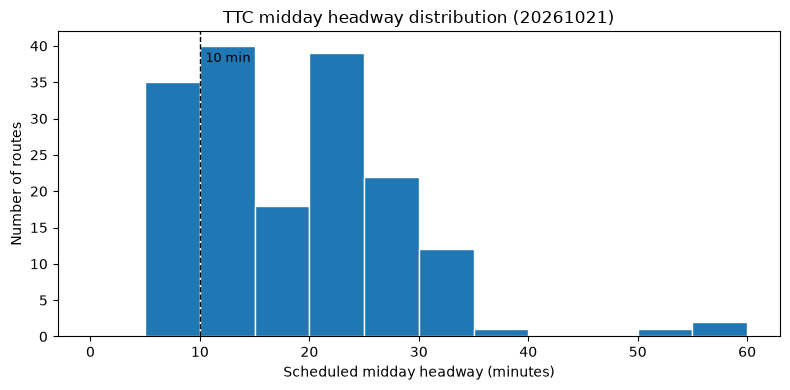

In [ ]:
hw.to_csv(OUT / f"scheduled_headway_{SERVICE_DATE}.csv")

ax = hw["Midday"].dropna().plot.hist(bins=range(0, 65, 5), figsize=(8, 4), edgecolor="white")
ax.axvline(FREQUENT_MIN, color="black", linestyle="--", linewidth=1)
ax.text(FREQUENT_MIN + 0.5, ax.get_ylim()[1] * 0.9, f"{FREQUENT_MIN} min", fontsize=9)
ax.set_xlabel("Scheduled midday headway (minutes)")
ax.set_ylabel("Number of routes")
ax.set_title(f"TTC midday headway distribution ({SERVICE_DATE})")
plt.tight_layout()
plt.savefig(OUT / "midday_headway_hist.png", dpi=150)
plt.show()

## 6. Study routes: baseline by direction and segment

This is the **planned** side of the planned-vs-actual comparison. The realtime analysis compares each study route against these numbers, so the baseline is kept:

- **by direction**: the two directions are separate streams of buses, and bunching usually builds in one direction only
- **by segment**: some routes have branches, so trunk stops (served by every branch) see far more buses than branch stops

### 6.1 Headway by direction

In [ ]:
short_name = routes.set_index("route_id")["route_short_name"]
study_ids = routes.loc[routes["route_short_name"].isin(STUDY), "route_id"]

def order_by_study(df, extra=("direction_id",)):
    # pivot tables sort route_id alphabetically; reorder rows to follow STUDY
    df = df.reset_index()
    df["route"] = pd.Categorical(df["route_id"].map(short_name), categories=STUDY, ordered=True)
    return df.sort_values(["route", *extra]).set_index(["route", *extra]).drop(columns="route_id")

baseline = (
    counts[counts["route_id"].isin(study_ids)]
          .pivot_table(index=["route_id", "direction_id"], columns="period", values="headway_min")
          .reindex(columns=list(PERIODS))
          .round(1)
)
if "trip_headsign" in day_trips.columns:
    # label each direction with its most common headsign (direction_id 0/1 does not mean a compass direction)
    names = (day_trips[day_trips["route_id"].isin(study_ids)]
             .groupby(["route_id", "direction_id"])["trip_headsign"]
             .agg(lambda s: s.value_counts().index[0]))
    baseline.insert(0, "headsign", names)

baseline = order_by_study(baseline)
baseline.to_csv(OUT / f"baseline_by_direction_{SERVICE_DATE}.csv")
baseline

period                                                       headsign  \
route direction_id                                                      
504   0                  West - 504A King towards Dundas West Station   
      1                    East - 504B King towards Broadview Station   
25    0             South - 25B Don Mills towards Broadview Statio...   
      1                         North - 25C Don Mills towards Steeles   
29    0             South - 29A Dufferin towards Exhibition (Duffe...   
      1                    North - 29 Dufferin towards Wilson Station   
929   0             South - 929 Dufferin Express towards Exhibitio...   
      1             North - 929 Dufferin Express towards Wilson St...   
39    0                    West - 39 Finch East towards Finch Station   
      1             East - 39B Finch East towards Old Finch and Mo...   
939   0             West - 939B Finch Express towards Finch West S...   
      1             East - 939B Finch Express towards Kennedy Stn ...   

period              AM peak  Midday  PM peak  Evening  Late evening  
route direction_id                                                   
504   0                 8.2     8.2     10.0      9.5           9.5  
      1                 8.6     9.0     10.0      9.0           9.5  
25    0                 5.3     5.8      5.0      6.0           6.0  
      1                 5.5     5.9      4.8      5.8           6.0  
29    0                 8.2     8.0      8.0      7.8           9.5  
      1                 9.0     7.8      8.0      7.8           9.5  
929   0                 9.5     8.0      8.0      7.8          51.4  
      1                 9.0     7.8      8.0      7.8          60.0  
39    0                 9.0     9.0      8.9      8.6           9.0  
      1                 9.0     9.0      8.6      9.0           9.0  
939   0                10.0    13.3     15.0      9.5          13.8  
      1                 8.6     7.8     15.0      9.5          13.8

### 6.2 Branch check

For each route and direction, compare the number of midday trips at its least and most served stops. A `max/min` ratio near **1** means every stop gets the same service; around **2 or more** means branches (or a few occasional trips to an extension).

In [ ]:
mid = per_stop[per_stop["route_id"].isin(study_ids) & (per_stop["period"] == "Midday")].copy()
mid["route"] = mid["route_id"].map(short_name)

check = mid.groupby(["route", "direction_id"])["trips"].agg(["count", "min", "median", "max"])
check["max/min"] = (check["max"] / check["min"]).round(1)
check.reindex(STUDY, level="route")

count  min  median  max  max/min
route direction_id                                  
504   0                55   37    44.0   83      2.2
      1                52   38    40.0   81      2.1
25    0                53   60    62.0   63      1.0
      1                57   60    61.0   61      1.0
29    0                49   22    45.0   46      2.1
      1                49   22    46.0   47      2.1
929   0                22   45    45.0   46      1.0
      1                22   45    46.0   47      1.0
39    0                72    4    40.0   45     11.2
      1                69    3    40.0   45     15.0
939   0                48    5    27.0   52     10.4
      1                45   11    46.0   57      5.2

### 6.3 Classify stops into trunk, branch and occasional

Each stop is compared with the busiest stop on the same route and direction (midday, the most stable period):

| Segment | Share of the busiest stop's trips | Meaning |
| --- | --- | --- |
| trunk | ≥ 75% | almost every trip passes |
| branch | 25–75% | only some trips pass, e.g. one of two branches |
| occasional | < 25% | a few trips only (extensions, special trips); **excluded from the baseline** |

Shares are used instead of fixed trip counts so one rule works for routes of any frequency. The thresholds are heuristic; section 6.5 tests how sensitive the result is to them.

In [ ]:
seg = mid.copy()
seg["share"] = seg["trips"] / seg.groupby(["route_id", "direction_id"])["trips"].transform("max")

def classify(share, trunk_min=TRUNK_MIN, occasional_max=OCCASIONAL_MAX):
    return pd.cut(share, bins=[0, occasional_max, trunk_min, 1.01],
                  labels=["occasional", "branch", "trunk"], right=False).astype(str)

seg["segment"] = classify(seg["share"])
seg.to_csv(OUT / f"stop_segments_{SERVICE_DATE}.csv", index=False)   # reused by the realtime analysis

(seg.groupby(["route", "direction_id", "segment"]).size()
    .unstack(fill_value=0)
    .reindex(columns=["trunk", "branch", "occasional"], fill_value=0)
    .reindex(STUDY, level="route"))

segment             trunk  branch  occasional
route direction_id                           
504   0                22      33           0
      1                22      30           0
25    0                53       0           0
      1                57       0           0
29    0                44       5           0
      1                43       6           0
929   0                22       0           0
      1                22       0           0
39    0                49      13          10
      1                48      12           9
939   0                21       7          20
      1                23       5          17

### 6.4 Baseline headway by segment

In [ ]:
ps = per_stop.merge(seg[["route_id", "direction_id", "stop_id", "segment"]],
                    on=["route_id", "direction_id", "stop_id"])
bs = (
    ps[ps["segment"] != "occasional"]
      .groupby(["route_id", "direction_id", "segment", "period"])["trips"].median()
      .reset_index()
)
bs["headway_min"] = bs["period"].map(lambda p: (PERIODS[p][1] - PERIODS[p][0]) * 60) / bs["trips"]

baseline_seg = (
    bs.pivot_table(index=["route_id", "direction_id", "segment"], columns="period", values="headway_min")
      .reindex(columns=list(PERIODS))
      .round(1)
      .reset_index()
)
baseline_seg["segment"] = pd.Categorical(baseline_seg["segment"], categories=["trunk", "branch"], ordered=True)
baseline_seg = order_by_study(baseline_seg.set_index(["route_id", "direction_id", "segment"]),
                              extra=("direction_id", "segment"))
baseline_seg.to_csv(OUT / f"baseline_by_segment_{SERVICE_DATE}.csv")
baseline_seg

period                      AM peak  Midday  PM peak  Evening  Late evening
route direction_id segment                                                 
504   0            trunk        4.0     4.4      4.9      4.9           5.0
                   branch       8.6     9.2     10.0      9.5          10.0
      1            trunk        4.7     4.6      5.0      4.6           4.9
                   branch       9.0     9.2     10.0      9.5           9.5
25    0            trunk        5.3     5.8      5.0      6.0           6.0
      1            trunk        5.5     5.9      4.8      5.8           6.0
29    0            trunk        8.2     8.0      8.0      7.8           9.5
                   branch      18.0    15.7     16.0     15.0          18.0
      1            trunk        8.6     7.8      8.0      7.5           9.5
                   branch      15.7    15.7     16.0     15.0          20.0
929   0            trunk        9.5     8.0      8.0      7.8          51.4
      1            trunk        9.0     7.8      8.0      7.8          60.0
39    0            trunk        8.6     9.0      8.9      8.6           9.0
                   branch      18.0    18.0     17.1     16.4          18.0
      1            trunk        8.6     8.8      8.6      9.0           8.6
                   branch      18.0    18.0     17.1     16.4          18.0
939   0            trunk        5.0     7.5      7.5      9.5          13.8
                   branch      10.0    13.3     14.1     18.0          90.0
      1            trunk        6.4     7.5      7.5      9.0          13.8
                   branch      10.6    13.3     15.0     15.0          60.0

### 6.5 Sensitivity test

The trunk and occasional thresholds are assumptions. If the classification stays the same over a range of thresholds, the conclusion does not depend on the exact choice. Counts are trunk (or occasional) stops per route, both directions combined.

In [ ]:
for t in [0.6, 0.7, 0.75, 0.8, 0.9]:
    n = (classify(seg["share"], trunk_min=t) == "trunk").groupby(seg["route"]).sum().reindex(STUDY, fill_value=0)
    print(f"trunk threshold {t:.0%}: ", n.to_dict())

print()
for o in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4]:
    n = (classify(seg["share"], occasional_max=o) == "occasional").groupby(seg["route"]).sum().reindex(STUDY, fill_value=0)
    print(f"occasional threshold {o:.0%}: ", n.to_dict())

trunk threshold 60%:  {'504': 44, '25': 110, '29': 87, '929': 44, '39': 97, '939': 44}
trunk threshold 70%:  {'504': 44, '25': 110, '29': 87, '929': 44, '39': 97, '939': 44}
trunk threshold 75%:  {'504': 44, '25': 110, '29': 87, '929': 44, '39': 97, '939': 44}
trunk threshold 80%:  {'504': 44, '25': 110, '29': 87, '929': 44, '39': 97, '939': 44}
trunk threshold 90%:  {'504': 44, '25': 110, '29': 87, '929': 44, '39': 52, '939': 22}

occasional threshold 10%:  {'504': 0, '25': 0, '29': 0, '929': 0, '39': 7, '939': 16}
occasional threshold 15%:  {'504': 0, '25': 0, '29': 0, '929': 0, '39': 7, '939': 20}
occasional threshold 20%:  {'504': 0, '25': 0, '29': 0, '929': 0, '39': 19, '939': 29}
occasional threshold 25%:  {'504': 0, '25': 0, '29': 0, '929': 0, '39': 19, '939': 37}
occasional threshold 30%:  {'504': 0, '25': 0, '29': 0, '929': 0, '39': 19, '939': 37}
occasional threshold 40%:  {'504': 0, '25': 0, '29': 0, '929': 0, '39': 19, '939': 37}


### 6.6 Inspect occasional stops

Occasional stops are worth a look: they are places a route nominally serves but where buses are rare.

In [ ]:
occ = (seg[seg["segment"] == "occasional"]
       .merge(stops[["stop_id", "stop_name"]], on="stop_id")
       [["route", "direction_id", "stop_name", "trips", "share"]]
       .sort_values(["route", "direction_id", "trips"]))
occ["share"] = occ["share"].round(2)
occ

,route,direction_id,stop_name,trips,share
0,39,0,Victoria Park Ave at Pawnee Ave,4,0.09
3,39,0,Victoria Park Ave at Hare Gate,4,0.09
6,39,0,Victoria Park Ave at Navaho Dr,4,0.09
8,39,0,Victoria Park Ave at Finch Ave East,4,0.09
2,39,0,480 Gordon Baker Rd,7,0.16
5,39,0,Gordon Baker Rd at Sparks Ave,7,0.16
7,39,0,Opposite 455 Gordon Baker Rd,7,0.16
1,39,0,McNicoll Ave at Victoria Park Ave,8,0.18
4,39,0,Harold Evans Cres at Gordon Baker Rd East Side,8,0.18
9,39,0,Harold Evans Cres at Tempo Ave,8,0.18


### 6.7 Findings (timetable for Wednesday 21 October 2026)

- **TTC splits runs at subway stations**: counting trips at their first stop double-counted routes 25, 47 and 63, roughly halving their headways. Measuring at each stop fixed this.
- **504 King**: trunk stops are served about every **4.5 min** at midday; each branch (504A, 504B) about every **9 min**.
- **25 Don Mills** and **929 Dufferin Express** have no branches (max/min ≈ 1.0).
- **29 Dufferin**: trunk about every 8 min; a short tail served by about half the trips (≈ 16 min).
- **39 Finch East**: trunk about every 9 min, a branch at ≈ 18 min, plus a few occasional stops.
- **939 Finch Express is more frequent than the local 39** on the shared trunk (≈ 7.5 vs 9 min midday) and is boosted to ≈ 5 min in the AM peak. Splitting by segment removed the earlier east/west mismatch (13.3 vs 7.8 min).
- **939 extension**: about 20 stops east of Markham Rd and in a loop via Staines Rd / Nightstar Rd / Seasons Dr see only ~1–2 buses an hour at midday, and appear to be served local rather than express.
- **Threshold sensitivity**: the trunk classification is unchanged for thresholds between 60% and 80%; at 90% short-turning trips on 39 and 939 start to be misclassified.

*Re-running with a newer timetable will change these numbers; update this cell to match.*

## 7. Flag frequent stops

A stop is frequent if **any** frequent route serves it. Coordinates are reprojected from latitude/longitude (EPSG:4326) to the metric EPSG:2952 so a 500 m buffer is accurate.

In [ ]:
stop_routes = (
    st[["trip_id", "stop_id"]].drop_duplicates()
      .merge(day_trips[["trip_id", "route_id"]], on="trip_id")[["stop_id", "route_id"]]
      .drop_duplicates()
)
freq_routes = set(hw.index[hw["frequent"]])
is_freq_stop = stop_routes.assign(f=stop_routes["route_id"].isin(freq_routes)).groupby("stop_id")["f"].any()

served = stops["stop_id"].isin(is_freq_stop.index).to_numpy()
gstops = gpd.GeoDataFrame(
    stops[served].copy(),
    geometry=gpd.points_from_xy(stops["stop_lon"].astype(float), stops["stop_lat"].astype(float))[served],
    crs="EPSG:4326",
).to_crs(CRS_M)
gstops["frequent"] = gstops["stop_id"].map(is_freq_stop)
print(f"Stops served on this date: {len(gstops):,}, of which frequent: {gstops['frequent'].sum():,}")

Stops served on this date: 9,076, of which frequent: 3,035


## 8. 500 m catchment

Buffer each frequent stop by 500 m and dissolve the buffers into one area. Stops outside that area have no frequent service nearby and are **service gap** candidates.

In [ ]:
freq_area = gstops.loc[gstops["frequent"]].buffer(WALK_M).union_all()
gstops["near_frequent"] = gstops.within(freq_area)

share = gstops["near_frequent"].mean()
gaps = gstops[~gstops["near_frequent"]]
print(f"{share:.1%} of stops are within {WALK_M} m of a frequent stop; {len(gaps):,} stops are outside")
print(f"Frequent catchment area: {freq_area.area / 1e6:,.1f} km²")

62.3% of stops are within 500 m of a frequent stop; 3,424 stops are outside
Frequent catchment area: 339.1 km²


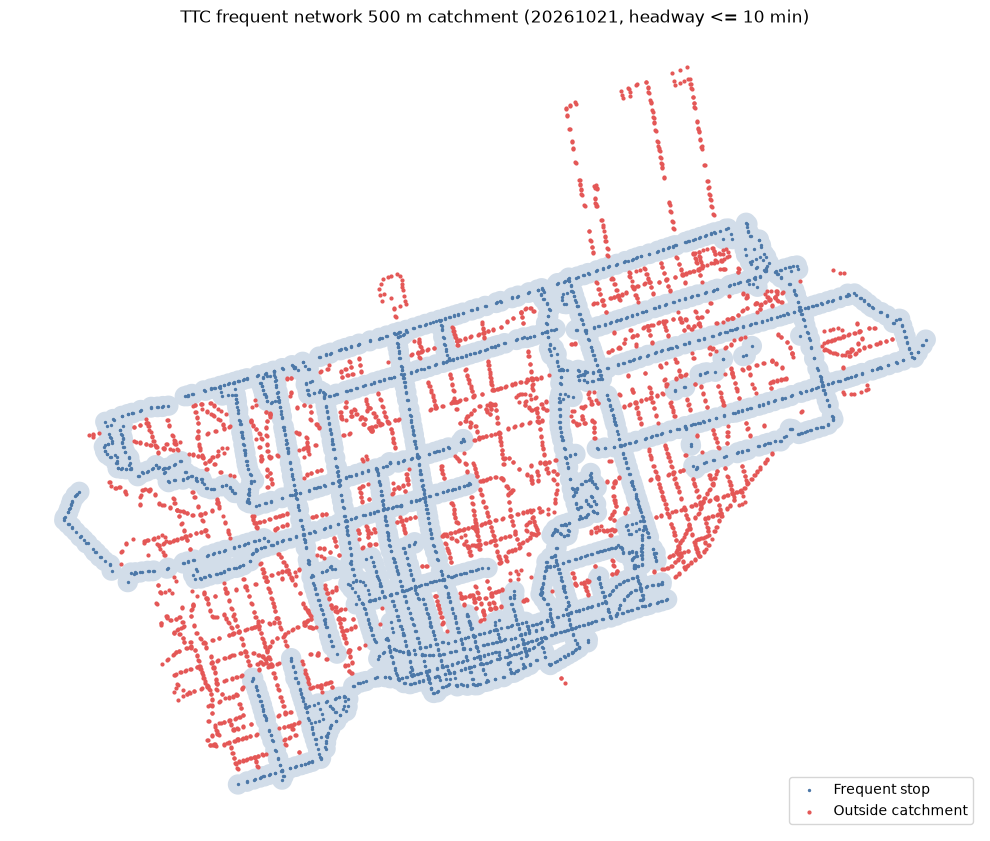

In [ ]:
fig, ax = plt.subplots(figsize=(10, 9))
gpd.GeoSeries([freq_area], crs=CRS_M).plot(ax=ax, color="#4C78A8", alpha=0.25)
gstops[gstops["frequent"]].plot(ax=ax, color="#4C78A8", markersize=2, label="Frequent stop")
gaps.plot(ax=ax, color="#E45756", markersize=4, label="Outside catchment")
ax.set_title(f"TTC frequent network {WALK_M} m catchment ({SERVICE_DATE}, headway <= {FREQUENT_MIN} min)")
ax.set_axis_off()
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUT / "frequent_coverage_map.png", dpi=150)
plt.show()

Export GeoJSON for further mapping in QGIS, ArcGIS or Power BI.

In [ ]:
gpd.GeoDataFrame(geometry=[freq_area], crs=CRS_M).to_crs("EPSG:4326").to_file(OUT / "frequent_coverage.geojson", driver="GeoJSON")
gstops.to_crs("EPSG:4326")[["stop_id", "stop_name", "frequent", "near_frequent", "geometry"]].to_file(
    OUT / "stops_coverage.geojson", driver="GeoJSON"
)
print("Written:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

Written:
  baseline_by_direction_20261021.csv
  baseline_by_segment_20261021.csv
  frequent_coverage.geojson
  frequent_coverage_map.png
  midday_headway_hist.png
  scheduled_headway_20261021.csv
  stop_segments_20261021.csv
  stops_coverage.geojson


## 9. (Optional) Population coverage

To estimate how many residents live within 500 m of a frequent stop, you need Statistics Canada dissemination area (DA) boundaries and population counts (free to download).

Join the two, save them as one file with a population column, then set `DA_FILE` and `POP_COL`. DA centroids are used to decide coverage: simple, but less accurate where DAs are large.

In [ ]:
DA_FILE = None          # e.g. Path("../data/census/toronto_da_pop.gpkg")
POP_COL = "population"

if DA_FILE and Path(DA_FILE).exists():
    da = gpd.read_file(DA_FILE).to_crs(CRS_M)
    da["covered"] = da.geometry.centroid.within(freq_area)
    covered = da.loc[da["covered"], POP_COL].sum()
    total = da[POP_COL].sum()
    print(f"About {covered:,.0f} of {total:,.0f} residents ({covered / total:.1%}) live within {WALK_M} m of a frequent stop (DA centroid method)")
else:
    print("DA_FILE not set; skipping population analysis")

DA_FILE not set; skipping population analysis


## 10. Limitations (state these in the README)

- **Straight-line distance**: the 500 m buffer is as the crow flies; real walking routes are longer. Next step: network-based walksheds with OSMnx and OpenStreetMap
- **Median stop**: headway is the median across a route's timed stops, so branch segments and short-turn sections with more or fewer trips than typical are smoothed out
- **Route-level classification**: where several routes share a street, the combined headway is shorter than any single route. A stop-level "trips per hour, all routes" measure would capture this
- **One day only**: weekends and holidays differ; change `SERVICE_DATE` and rerun to compare
- **Frequent definition**: `FREQUENT_MIN` and `CORE_PERIODS` are assumptions and can be adjusted
- **Segment thresholds**: `TRUNK_MIN` and `OCCASIONAL_MAX` are heuristic; see the sensitivity test in section 6.5
- **Branches combined**: both 504 branches are labelled "branch" together; they have similar frequency, but could be separated by the branch letter in `trip_headsign`
- **Late evening edge effect**: when a route ends service shortly after 22:00, only a few stops see its last trips, so the median stop count is tiny and late-evening headways can look absurd (e.g. 60–180 min). Late evening is not used to classify frequent routes